# 07b Spatial structure and predictors of shoreline change

**Manuscript outputs:** Tables 1 and 2; Figures 6, 7a, 7b and 8; statistics for Sections 4.1 and 4.2.1 to 4.2.5 (Outputs/Tables/Text_statistics)

**Inputs:** completed GLORYS attribution GeoPackage (stage 06)

Inputs are read from `Master_raw/`; everything produced is written to `Outputs/` (manuscript figures in `Outputs/Figures`, tables in `Outputs/Tables`). The first code cell lists every path. Run the cells in order.

# Spatial structure and predictors of shoreline change

**Author:** James Mbugua  
**Reg:** ENC324-9762/2022

This notebook evaluates transect-level shoreline-change spatial structure and relationships between shoreline change and GLORYS-derived sea-level metrics. Run cells from top to bottom.


## Package Integration


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy import stats
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from libpysal.weights import KNN
from libpysal.weights.spatial_lag import lag_spatial
from esda.moran import Moran, Moran_Local
import statsmodels.api as sm
from spreg import ML_Lag
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW


C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## File Mapping and Analysis Settings


In [3]:
from pathlib import Path

# ------------------------------------------------------------
# REPOSITORY ROOT: first folder above this notebook that contains Master_raw
# (e.g. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024)
# ------------------------------------------------------------
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "Master_raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No Master_raw folder found above {_here}. Open this notebook inside the repository.")
RAW = ROOT / "Master_raw"          # inputs
OUTPUTS = ROOT / "Outputs"         # everything this repository produces
FIGURES = OUTPUTS / "Figures"      # manuscript figures
TABLES = OUTPUTS / "Tables"        # manuscript tables
TEXT_STATS = TABLES / "Text_statistics"
for _d in (FIGURES, TABLES, TEXT_STATS):
    _d.mkdir(parents=True, exist_ok=True)
OVERWRITE = True                   # re-running replaces this notebook's earlier outputs


def first_existing(*candidates):
    """Return the first path that exists (otherwise the first one)."""
    for c in candidates:
        if Path(c).exists():
            return Path(c)
    return Path(candidates[0])


def save_table(df, name, index=False, folder=None):
    path = (folder or TABLES) / f"{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")
    print("Saved:", path.relative_to(ROOT))


def save_figure(fig, name, dpi=600):
    for ext in ("jpg",):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=dpi, bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
    print("Saved:", (FIGURES / f"{name}.jpg").relative_to(ROOT))


def remove_existing(*files):
    for f in map(Path, files):
        for t in (list(f.parent.glob(f.stem + ".*")) if f.suffix == ".shp" else [f]):
            if t.exists():
                if not OVERWRITE:
                    raise FileExistsError(t)
                t.unlink()

# ------------------------------------------------------------
# INPUTS AND OUTPUT FOLDERS FOR THIS NOTEBOOK
# ------------------------------------------------------------
TRANSECT_RATES_DIR = RAW / "Transect_rates"
GLORYS_DIR = OUTPUTS / "GLORYS_attribution"
COMPLETE_GPKG = first_existing(GLORYS_DIR / "ke_transects_GLORYS_complete_attribution_zoned.gpkg",
                               TRANSECT_RATES_DIR / "ke_transects_GLORYS_complete_attribution_zoned.gpkg")
SUMMARY = OUTPUTS / "Erosion_Geostats_summary"
PRIMARY_CSV = SUMMARY / "A_Shoreline" / "transect_primary_analysis.csv"
CELL_INPUT_CSV = SUMMARY / "B_GLORYS_Cell" / "glorys_cell_geostatistical_input.csv"

print("Repository root:", ROOT)
for _label, _p in [("COMPLETE_GPKG", COMPLETE_GPKG)]:
    print(f"  {'ok     ' if _p.exists() else 'MISSING'} {_label}: {_p.relative_to(ROOT)}")

# Project root
PROJECT_DIR = ROOT

# Input master dataset
# Read the stage 06 output directly (no manual copy to Master_raw needed)
MASTER_GPKG = COMPLETE_GPKG
LAYER = "transects_complete"

# Main output directories
OUTPUT_DIR = SUMMARY
A_OUT = OUTPUT_DIR / "A_Shoreline"
B_OUT = OUTPUT_DIR / "B_GLORYS_Cell"
GEO_OUT = A_OUT / "Geostatistics"

# Analysis files
PRIMARY_CSV = A_OUT / "transect_primary_analysis.csv"
CELL_CSV = B_OUT / "glorys_cell_geostatistical_input.csv"
CELL_GPKG = B_OUT / "glorys_cell_geostatistical_input.gpkg"

# Create output folders
for folder in [A_OUT, B_OUT, GEO_OUT]:
    folder.mkdir(parents=True, exist_ok=True)

# Analysis settings
EXCLUDE_PROVISIONAL = True
K_TRANSECT = 4
GLOBAL_PERMUTATIONS = 999
LISA_PERMUTATIONS = 999
ALPHA = 0.05
SEED = 42

# Verify primary input
assert MASTER_GPKG.exists(), f"Missing master GeoPackage: {MASTER_GPKG}"
print("Master GeoPackage found:", MASTER_GPKG)
print("Output directory:", OUTPUT_DIR)


Repository root: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
  ok      COMPLETE_GPKG: Outputs\GLORYS_attribution\ke_transects_GLORYS_complete_attribution_zoned.gpkg
Master GeoPackage found: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\ke_transects_GLORYS_complete_attribution_zoned.gpkg
Output directory: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary


## A. Shoreline change: source and descriptive results
### A1. Validate the master GeoPackage
The source contains 12,455 transects, 47 GLORYS cell IDs and three coastal zones in its saved output. Check the attribution status before cell-level inference; provisional GLORYS assignments are not independent measurements.

In [4]:
# A1. Load and validate the master GeoPackage BEFORE creating the primary CSV.
LAYER = 'transects_complete'
gdf = gpd.read_file(MASTER_GPKG, layer=LAYER)
required = ['Transect_ID', 'Pixel_ID', 'Grid_Lon', 'Grid_Lat', 'WLR', 'EPR', 'NSM',
            'SL_Trend_mm_yr', 'SL_Variability_m', 'Assignment_Status', 'Zone']
missing = sorted(set(required) - set(gdf.columns))
assert not missing, f'Missing required fields: {missing}'
assert gdf.crs is not None, 'GeoPackage lacks a CRS'
assert not gdf.geometry.isna().any(), 'Missing transect geometry'
assert gdf['Transect_ID'].notna().all() and gdf['Transect_ID'].is_unique, 'Transect_ID missing/duplicated'
print('Transects:', len(gdf), '| CRS:', gdf.crs, '| GLORYS cells:', gdf['Pixel_ID'].nunique())
print('Assignment statuses:\n', gdf['Assignment_Status'].value_counts(dropna=False))
print('Zones:\n', gdf['Zone'].value_counts(dropna=False))


Transects: 12455 | CRS: EPSG:32737 | GLORYS cells: 47
Assignment statuses:
 Assignment_Status
DIRECT_MID                   12102
DIRECT_START                   208
NEAREST_OCEAN_PROVISIONAL      145
Name: count, dtype: int64
Zones:
 Zone
Kilifi           5445
Kwale-Mombasa    3910
Tana-Manda       3100
Name: count, dtype: int64


### A2. Export the primary transect CSV
The source notebook identifies three WLR values around `9999.99` (transects 3143–3145) as suspected sentinels. **Confirm their invalid status against DSAS** before treating them as missing. The source GeoPackage is never modified.

In [5]:
# A2. Create the analysis CSV; do not modify the master GeoPackage.
# Apply this rule only if 9999.99 has been confirmed as an invalid WLR code.
primary = pd.DataFrame(gdf.drop(columns=gdf.geometry.name)).copy()
primary['WLR'] = pd.to_numeric(primary['WLR'], errors='coerce')
invalid_wlr = np.isclose(primary['WLR'], 9999.99, rtol=0, atol=0.001)
print('WLR values flagged for replacement:', int(invalid_wlr.sum()))
print(primary.loc[invalid_wlr, ['Transect_ID', 'WLR', 'EPR', 'NSM']].to_string(index=False))
primary.loc[invalid_wlr, 'WLR'] = np.nan
primary.to_csv(PRIMARY_CSV, index=False)
reloaded = pd.read_csv(PRIMARY_CSV, low_memory=False)
assert len(reloaded) == len(gdf)
assert list(primary.columns) == list(reloaded.columns)
assert not np.isclose(pd.to_numeric(reloaded['WLR'], errors='coerce'), 9999.99, rtol=0, atol=0.001).any()
print('Primary CSV:', PRIMARY_CSV.resolve(), '| rows:', len(reloaded),
      '| fields:', len(reloaded.columns), '| WLR values corrected:', int(invalid_wlr.sum()))


WLR values flagged for replacement: 3
 Transect_ID         WLR       EPR        NSM
        3143 9999.990234 36.001385  38.565868
        3144 9999.990234 14.094456  29.308746
        3145 9999.990234 12.626114 101.216461
Primary CSV: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\transect_primary_analysis.csv | rows: 12455 | fields: 38 | WLR values corrected: 3


### A3. Coast-wide descriptive statistics
Summarise EPR, WLR and NSM separately; NSM is in metres, whereas EPR and WLR are rates. The three invalid WLR values remain excluded from WLR statistics only.

In [6]:
# 1. Read the primary CSV
df = pd.read_csv(PRIMARY_CSV, low_memory=False)

# 2. Define metrics and units
metrics = {
    'EPR': 'EPR (m yr⁻¹)',
    'WLR': 'WLR (m yr⁻¹)',
    'NSM': 'NSM (m)'
}

# 3. Calculate descriptive statistics
summary = []

for col, label in metrics.items():

    values = pd.to_numeric(
        df[col],
        errors='coerce'
    ).dropna()

    summary.append({
        'Metric': label,
        'n (transects)': len(values),
        'Mean': values.mean(),
        'Median': values.median(),
        'Std Dev': values.std(ddof=1)
    })

# 4. Create summary table
summary_df = pd.DataFrame(summary)

# 5. Round numerical values to 2 decimal places
summary_df = summary_df.round({
    'Mean': 2,
    'Median': 2,
    'Std Dev': 2
})

# 6. Display manuscript-ready table
print("\nTable: Descriptive statistics of shoreline change")

display(
    summary_df.style
    .format({
        'n (transects)': '{:,.0f}',
        'Mean': '{:.2f}',
        'Median': '{:.2f}',
        'Std Dev': '{:.2f}'
    })
    .hide(axis='index')
)
save_table(summary_df, "Table_1_National_shoreline_change_summary")



Table: Descriptive statistics of shoreline change


Metric,n (transects),Mean,Median,Std Dev
EPR (m yr⁻¹),"12,455",0.33,0.04,4.80
WLR (m yr⁻¹),"12,452",0.18,0.02,4.95
NSM (m),"12,455",9.49,1.00,95.92


Saved: Outputs\Tables\Table_1_National_shoreline_change_summary.csv



## A3.1 WLR confidence-interval classification by coastal zone


In [7]:
# ============================================================
# COMBINED ZONAL SHORELINE-CHANGE SUMMARY
# Descriptive statistics + WLR 90% CI classification
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display


# ------------------------------------------------------------
# 1. READ PRIMARY TRANSECT DATA
# ------------------------------------------------------------

df = pd.read_csv(PRIMARY_CSV, low_memory=False)

required = [
    'Transect_ID',
    'Zone',
    'EPR',
    'WLR',
    'WCI',
    'NSM'
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise KeyError(
        f"Required field(s) missing: {missing}"
    )


# ------------------------------------------------------------
# 2. CONVERT NUMERIC FIELDS
# ------------------------------------------------------------

for col in ['EPR', 'WLR', 'WCI', 'NSM']:
    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )


# ------------------------------------------------------------
# 3. DESCRIPTIVE STATISTICS BY ZONE
# ------------------------------------------------------------

descriptive = (
    df.groupby('Zone')
    .agg(
        n_records=('Transect_ID', 'count'),
        n_valid_WLR=('WLR', 'count'),

        Mean_EPR=('EPR', 'mean'),
        Median_EPR=('EPR', 'median'),
        SD_EPR=('EPR', 'std'),

        Mean_WLR=('WLR', 'mean'),
        Median_WLR=('WLR', 'median'),
        SD_WLR=('WLR', 'std'),

        Mean_NSM=('NSM', 'mean'),
        Median_NSM=('NSM', 'median'),
        SD_NSM=('NSM', 'std')
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. RETAIN VALID WLR + WCI PAIRS
# ------------------------------------------------------------

wlr_ci = df.loc[
    df['WLR'].notna() &
    df['WCI'].notna()
].copy()

# WCI represents confidence-interval half-width
wlr_ci['WCI'] = wlr_ci['WCI'].abs()


# ------------------------------------------------------------
# 5. CALCULATE WLR 90% CI
# ------------------------------------------------------------

wlr_ci['WLR_CI90_lower'] = (
    wlr_ci['WLR'] - wlr_ci['WCI']
)

wlr_ci['WLR_CI90_upper'] = (
    wlr_ci['WLR'] + wlr_ci['WCI']
)


# ------------------------------------------------------------
# 6. CLASSIFY EACH TRANSECT
# ------------------------------------------------------------

conditions = [
    # Entire CI below zero
    wlr_ci['WLR_CI90_upper'] < 0,

    # Entire CI above zero
    wlr_ci['WLR_CI90_lower'] > 0
]

choices = [
    'Significantly eroding',
    'Significantly accreting'
]

wlr_ci['WLR_status_90CI'] = np.select(
    conditions,
    choices,
    default='Not statistically distinguishable from stability'
)


# ------------------------------------------------------------
# 7. CALCULATE ZONAL CLASSIFICATION COUNTS
# ------------------------------------------------------------

classification_counts = (
    wlr_ci
    .groupby(
        ['Zone', 'WLR_status_90CI']
    )
    .size()
    .unstack(fill_value=0)
)

status_order = [
    'Significantly eroding',
    'Significantly accreting',
    'Not statistically distinguishable from stability'
]

classification_counts = classification_counts.reindex(
    columns=status_order,
    fill_value=0
)

classification_counts['n_classified'] = (
    classification_counts[status_order]
    .sum(axis=1)
)


# ------------------------------------------------------------
# 8. CONVERT CLASSIFICATIONS TO PERCENTAGES
# ------------------------------------------------------------

classification_counts[
    'Significantly eroding (%)'
] = (
    classification_counts['Significantly eroding']
    / classification_counts['n_classified']
    * 100
)

classification_counts[
    'Significantly accreting (%)'
] = (
    classification_counts['Significantly accreting']
    / classification_counts['n_classified']
    * 100
)

classification_counts[
    'Not distinguishable from stability (%)'
] = (
    classification_counts[
        'Not statistically distinguishable from stability'
    ]
    / classification_counts['n_classified']
    * 100
)


# ------------------------------------------------------------
# 9. MERGE DESCRIPTIVE + CLASSIFICATION RESULTS
# ------------------------------------------------------------

classification_table = (
    classification_counts[
        [
            'n_classified',
            'Significantly eroding (%)',
            'Significantly accreting (%)',
            'Not distinguishable from stability (%)'
        ]
    ]
    .reset_index()
)

combined = descriptive.merge(
    classification_table,
    on='Zone',
    how='left'
)


# ------------------------------------------------------------
# 10. MANUSCRIPT ZONE ORDER
# ------------------------------------------------------------

zone_order = [
    'Kilifi',
    'Kwale-Mombasa',
    'Tana-Manda'
]

combined['_order'] = pd.Categorical(
    combined['Zone'],
    categories=zone_order,
    ordered=True
)

combined = (
    combined
    .sort_values('_order')
    .drop(columns='_order')
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. QC
# ------------------------------------------------------------

print("\nQUALITY CONTROL")
print("------------------------------")

print(
    f"Total source records: "
    f"{len(df):,}"
)

print(
    f"Valid WLR: "
    f"{df['WLR'].notna().sum():,}"
)

print(
    f"Valid WLR + WCI: "
    f"{len(wlr_ci):,}"
)

print(
    f"Classified transects: "
    f"{combined['n_classified'].sum():,.0f}"
)

# Check n_valid_WLR against n_classified
combined['WLR_count_check'] = (
    combined['n_valid_WLR']
    == combined['n_classified']
)

print("\nWLR count agreement by zone:")

print(
    combined[
        [
            'Zone',
            'n_valid_WLR',
            'n_classified',
            'WLR_count_check'
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 12. ROUND FOR MANUSCRIPT TABLE
# ------------------------------------------------------------

stat_cols = [
    'Mean_EPR',
    'Median_EPR',
    'SD_EPR',
    'Mean_WLR',
    'Median_WLR',
    'SD_WLR',
    'Mean_NSM',
    'Median_NSM',
    'SD_NSM',
    'Significantly eroding (%)',
    'Significantly accreting (%)',
    'Not distinguishable from stability (%)'
]

combined[stat_cols] = (
    combined[stat_cols].round(2)
)


# ------------------------------------------------------------
# 13. CREATE CLEAN MANUSCRIPT TABLE
# ------------------------------------------------------------

manuscript_table = combined[
    [
        'Zone',
        'n_valid_WLR',

        'Mean_EPR',
        'Median_EPR',
        'SD_EPR',

        'Mean_WLR',
        'Median_WLR',
        'SD_WLR',

        'Mean_NSM',
        'Median_NSM',
        'SD_NSM',

        'Significantly eroding (%)',
        'Significantly accreting (%)',
        'Not distinguishable from stability (%)'
    ]
].copy()

manuscript_table = manuscript_table.rename(
    columns={
        'n_valid_WLR': 'n',
        'Significantly eroding (%)':
            'Eroding (%)',
        'Significantly accreting (%)':
            'Accreting (%)',
        'Not distinguishable from stability (%)':
            'Not distinguishable (%)'
    }
)


# ------------------------------------------------------------
# 14. DISPLAY
# ------------------------------------------------------------

print(
    "\nTable: Shoreline change statistics and "
    "WLR confidence-interval classification by coastal zone"
)

display(
    manuscript_table.style
    .format({
        'n': '{:,.0f}',

        'Mean_EPR': '{:.2f}',
        'Median_EPR': '{:.2f}',
        'SD_EPR': '{:.2f}',

        'Mean_WLR': '{:.2f}',
        'Median_WLR': '{:.2f}',
        'SD_WLR': '{:.2f}',

        'Mean_NSM': '{:.2f}',
        'Median_NSM': '{:.2f}',
        'SD_NSM': '{:.2f}',

        'Eroding (%)': '{:.2f}',
        'Accreting (%)': '{:.2f}',
        'Not distinguishable (%)': '{:.2f}'
    })
    .hide(axis='index')
)


# ------------------------------------------------------------
# 15. EXPORT
# ------------------------------------------------------------

output_file = (
    A_OUT /
    "shoreline_summary_by_zone_with_WLR_90CI.csv"
)

manuscript_table.to_csv(
    output_file,
    index=False
)

print("\nSaved:")
print(output_file)
save_table(manuscript_table, "Table_2_Zonal_shoreline_change_and_WLR_90CI_classes")



QUALITY CONTROL
------------------------------
Total source records: 12,455
Valid WLR: 12,452
Valid WLR + WCI: 12,452
Classified transects: 12,452

WLR count agreement by zone:
         Zone  n_valid_WLR  n_classified  WLR_count_check
       Kilifi         5442          5442             True
Kwale-Mombasa         3910          3910             True
   Tana-Manda         3100          3100             True

Table: Shoreline change statistics and WLR confidence-interval classification by coastal zone


Zone,n,Mean_EPR,Median_EPR,SD_EPR,Mean_WLR,Median_WLR,SD_WLR,Mean_NSM,Median_NSM,SD_NSM,Eroding (%),Accreting (%),Not distinguishable (%)
Kilifi,"5,442",0.53,0.09,3.61,0.57,0.14,3.57,11.82,2.04,82.00,8.36,34.09,57.55
Kwale-Mombasa,"3,910",0.84,0.06,5.47,0.51,0.01,6.09,20.22,1.41,131.45,11.36,15.81,72.84
Tana-Manda,"3,100",-0.67,-0.14,5.51,-0.92,-0.25,5.28,-8.11,-3.34,53.88,36.23,5.97,57.81



Saved:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\shoreline_summary_by_zone_with_WLR_90CI.csv
Saved: Outputs\Tables\Table_2_Zonal_shoreline_change_and_WLR_90CI_classes.csv


In [8]:

# ============================================================
# WLR 90% CONFIDENCE-INTERVAL CLASSIFICATION
# Coast-wide and by coastal zone
#
# Classification:
#   Significantly eroding:
#       entire WLR 90% CI < 0
#
#   Significantly accreting:
#       entire WLR 90% CI > 0
#
#   Not statistically distinguishable from stability:
#       90% CI includes zero
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display


# ------------------------------------------------------------
# 1. INPUT
# ------------------------------------------------------------

OUT_DIR = PRIMARY_CSV.parent

print("Reading:")
print(PRIMARY_CSV)


# ------------------------------------------------------------
# 2. READ TRANSECT DATA
# ------------------------------------------------------------

df = pd.read_csv(PRIMARY_CSV, low_memory=False)

print(f"\nTotal transect records: {len(df):,}")


# ------------------------------------------------------------
# 3. CHECK REQUIRED FIELDS
#
# IMPORTANT:
# Your DSAS table contains WCI, not WCI90.
# ------------------------------------------------------------

required = [
    'Transect_ID',
    'WLR',
    'WCI',
    'Zone'
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise KeyError(
        f"Required field(s) missing: {missing}\n\n"
        f"Available fields:\n{df.columns.tolist()}"
    )

print("\nRequired fields found:")
print(required)


# ------------------------------------------------------------
# 4. CONVERT WLR AND WCI TO NUMERIC
# ------------------------------------------------------------

df['WLR'] = pd.to_numeric(
    df['WLR'],
    errors='coerce'
)

df['WCI'] = pd.to_numeric(
    df['WCI'],
    errors='coerce'
)

n_wlr = df['WLR'].notna().sum()

n_wci = df['WCI'].notna().sum()

n_pair = (
    df['WLR'].notna() &
    df['WCI'].notna()
).sum()

print("\nDATA AVAILABILITY")
print("-----------------")
print(f"Valid WLR:       {n_wlr:,}")
print(f"Valid WCI:       {n_wci:,}")
print(f"Valid WLR + WCI: {n_pair:,}")


# ------------------------------------------------------------
# 5. RETAIN VALID WLR + WCI PAIRS
# ------------------------------------------------------------

wlr_ci = df.loc[
    df['WLR'].notna() &
    df['WCI'].notna()
].copy()

# WCI is treated as the confidence-interval half-width.
# Ensure positive magnitude.
wlr_ci['WCI'] = wlr_ci['WCI'].abs()


# ------------------------------------------------------------
# 6. CALCULATE WLR 90% CI BOUNDS
# ------------------------------------------------------------

wlr_ci['WLR_CI90_lower'] = (
    wlr_ci['WLR'] - wlr_ci['WCI']
)

wlr_ci['WLR_CI90_upper'] = (
    wlr_ci['WLR'] + wlr_ci['WCI']
)


# ------------------------------------------------------------
# 7. CLASSIFY EACH TRANSECT
#
# Positive WLR = accretion
# Negative WLR = erosion
# ------------------------------------------------------------

conditions = [

    # Entire confidence interval below zero
    wlr_ci['WLR_CI90_upper'] < 0,

    # Entire confidence interval above zero
    wlr_ci['WLR_CI90_lower'] > 0
]

choices = [
    'Significantly eroding',
    'Significantly accreting'
]

wlr_ci['WLR_status_90CI'] = np.select(
    conditions,
    choices,
    default='Not statistically distinguishable from stability'
)


# ------------------------------------------------------------
# 8. COAST-WIDE SUMMARY
# ------------------------------------------------------------

status_order = [
    'Significantly eroding',
    'Significantly accreting',
    'Not statistically distinguishable from stability'
]

coastwide = (
    wlr_ci['WLR_status_90CI']
    .value_counts()
    .reindex(status_order, fill_value=0)
    .rename_axis('Classification')
    .reset_index(name='Transects')
)

coastwide['Percent'] = (
    coastwide['Transects']
    / len(wlr_ci)
    * 100
)

coastwide['Percent'] = coastwide['Percent'].round(2)


print("\n")
print("=" * 72)
print("COAST-WIDE WLR CLASSIFICATION USING 90% CONFIDENCE INTERVALS")
print("=" * 72)

display(
    coastwide.style.format({
        'Transects': '{:,.0f}',
        'Percent': '{:.2f}'
    }).hide(axis='index')
)


# ------------------------------------------------------------
# 9. ZONAL SUMMARY
# ------------------------------------------------------------

zone_order = [
    'Kilifi',
    'Kwale-Mombasa',
    'Tana-Manda'
]

# Check actual zone names
print("\nZones present in dataset:")
print(wlr_ci['Zone'].value_counts(dropna=False))


zone_summary = (
    wlr_ci
    .groupby(
        ['Zone', 'WLR_status_90CI'],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
)

# Ensure all three classification columns exist
zone_summary = zone_summary.reindex(
    columns=status_order,
    fill_value=0
)

# Put zones in manuscript order
existing_zones = [
    z for z in zone_order
    if z in zone_summary.index
]

zone_summary = zone_summary.reindex(existing_zones)

zone_summary['Total'] = zone_summary.sum(axis=1)


# ------------------------------------------------------------
# 10. CONVERT ZONAL COUNTS TO PERCENTAGES
# ------------------------------------------------------------

zone_percent = zone_summary[
    status_order
].div(
    zone_summary['Total'],
    axis=0
) * 100

zone_percent = zone_percent.round(2)


# ------------------------------------------------------------
# 11. CREATE MANUSCRIPT-READY ZONAL TABLE
# ------------------------------------------------------------

zone_results = pd.DataFrame({
    'Zone': zone_summary.index,

    'n': zone_summary['Total'].values,

    'Significantly eroding (%)':
        zone_percent[
            'Significantly eroding'
        ].values,

    'Significantly accreting (%)':
        zone_percent[
            'Significantly accreting'
        ].values,

    'Not distinguishable from stability (%)':
        zone_percent[
            'Not statistically distinguishable from stability'
        ].values
})


print("\n")
print("=" * 72)
print("WLR CLASSIFICATION BY COASTAL ZONE")
print("=" * 72)

display(
    zone_results.style.format({
        'n': '{:,.0f}',
        'Significantly eroding (%)': '{:.2f}',
        'Significantly accreting (%)': '{:.2f}',
        'Not distinguishable from stability (%)': '{:.2f}'
    }).hide(axis='index')
)


# ------------------------------------------------------------
# 12. QC CHECKS
# ------------------------------------------------------------

print("\n")
print("=" * 72)
print("QUALITY CONTROL")
print("=" * 72)

print(
    "Coast-wide classified transects:",
    f"{coastwide['Transects'].sum():,}"
)

print(
    "Valid WLR + WCI pairs:",
    f"{len(wlr_ci):,}"
)

print(
    "Coast-wide percentage total:",
    f"{coastwide['Percent'].sum():.2f}%"
)

print("\nZone percentage totals:")

for zone in zone_results['Zone']:

    row = zone_results.loc[
        zone_results['Zone'] == zone
    ].iloc[0]

    total_pct = (
        row['Significantly eroding (%)']
        + row['Significantly accreting (%)']
        + row['Not distinguishable from stability (%)']
    )

    print(
        f"  {zone}: {total_pct:.2f}%"
    )


# ------------------------------------------------------------
# 13. EXPORT RESULTS
# ------------------------------------------------------------

coastwide_file = (
    OUT_DIR /
    "WLR_90CI_classification_coastwide.csv"
)

zone_file = (
    OUT_DIR /
    "WLR_90CI_classification_by_zone.csv"
)

transect_file = (
    OUT_DIR /
    "WLR_90CI_classification_by_transect.csv"
)


coastwide.to_csv(
    coastwide_file,
    index=False
)

zone_results.to_csv(
    zone_file,
    index=False
)

wlr_ci[
    [
        'Transect_ID',
        'Zone',
        'WLR',
        'WCI',
        'WLR_CI90_lower',
        'WLR_CI90_upper',
        'WLR_status_90CI'
    ]
].to_csv(
    transect_file,
    index=False
)


print("\nSaved:")
print(coastwide_file)
print(zone_file)
print(transect_file)

Reading:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\transect_primary_analysis.csv

Total transect records: 12,455

Required fields found:
['Transect_ID', 'WLR', 'WCI', 'Zone']

DATA AVAILABILITY
-----------------
Valid WLR:       12,452
Valid WCI:       12,455
Valid WLR + WCI: 12,452


COAST-WIDE WLR CLASSIFICATION USING 90% CONFIDENCE INTERVALS


Classification,Transects,Percent
Significantly eroding,"2,022",16.24
Significantly accreting,"2,658",21.35
Not statistically distinguishable from stability,"7,772",62.42



Zones present in dataset:
Zone
Kilifi           5442
Kwale-Mombasa    3910
Tana-Manda       3100
Name: count, dtype: int64


WLR CLASSIFICATION BY COASTAL ZONE


Zone,n,Significantly eroding (%),Significantly accreting (%),Not distinguishable from stability (%)
Kilifi,"5,442",8.36,34.09,57.55
Kwale-Mombasa,"3,910",11.36,15.81,72.84
Tana-Manda,"3,100",36.23,5.97,57.81




QUALITY CONTROL
Coast-wide classified transects: 12,452
Valid WLR + WCI pairs: 12,452
Coast-wide percentage total: 100.01%

Zone percentage totals:
  Kilifi: 100.00%
  Kwale-Mombasa: 100.01%
  Tana-Manda: 100.01%

Saved:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\WLR_90CI_classification_coastwide.csv
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\WLR_90CI_classification_by_zone.csv
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\WLR_90CI_classification_by_transect.csv


### A4. Coastal-zone descriptive statistics
The source records use `Kilifi`, `Kwale-Mombasa` and `Tana-Manda`. Use their exact spellings for sorting. Descriptive summaries are not independent cell-level sea-level tests.

In [9]:
# 1. Read primary transect-level CSV
df = pd.read_csv(PRIMARY_CSV, low_memory=False)

# 2. Identify zone column
zone_cols = [
    c for c in df.columns
    if c.lower() == 'zone'
]

if not zone_cols:
    raise KeyError(
        "Zone column not found. Available zone-related fields: "
        + str([c for c in df.columns if 'zone' in c.lower()])
    )

ZONE_COL = zone_cols[0]

# 3. Convert shoreline metrics to numeric
metrics = ['EPR', 'WLR', 'NSM']

for col in metrics:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 4. Calculate zonal descriptive statistics
zone_summary = (
    df.groupby(ZONE_COL, dropna=False)
    .agg(
        n_transects=('Transect_ID', 'count'),

        Mean_EPR=('EPR', 'mean'),
        Median_EPR=('EPR', 'median'),
        SD_EPR=('EPR', 'std'),

        Mean_WLR=('WLR', 'mean'),
        Median_WLR=('WLR', 'median'),
        SD_WLR=('WLR', 'std'),

        Mean_NSM=('NSM', 'mean'),
        Median_NSM=('NSM', 'median'),
        SD_NSM=('NSM', 'std')
    )
    .reset_index()
    .rename(columns={ZONE_COL: 'Zone'})
)

# 5. Round statistics to two decimal places
numeric_cols = zone_summary.columns.difference(
    ['Zone', 'n_transects']
)

zone_summary[numeric_cols] = (
    zone_summary[numeric_cols].round(2)
)

# 6. Optional: organise zones in manuscript order
zone_order = [
    'Kilifi',
    'Kwale-Mombasa',
    'Tana-Manda'
]

zone_summary['_order'] = pd.Categorical(
    zone_summary['Zone'],
    categories=zone_order,
    ordered=True
)

zone_summary = (
    zone_summary
    .sort_values('_order', na_position='last')
    .drop(columns='_order')
    .reset_index(drop=True)
)

# 7. Display manuscript-ready table
print("\nTable: Shoreline change statistics by coastal zone")

display(
    zone_summary.style
    .format({
        'n_transects': '{:,.0f}',

        'Mean_EPR': '{:.2f}',
        'Median_EPR': '{:.2f}',
        'SD_EPR': '{:.2f}',

        'Mean_WLR': '{:.2f}',
        'Median_WLR': '{:.2f}',
        'SD_WLR': '{:.2f}',

        'Mean_NSM': '{:.2f}',
        'Median_NSM': '{:.2f}',
        'SD_NSM': '{:.2f}'
    })
    .hide(axis='index')
)

# 8. Verify transect counts
print("\nTotal transects:", zone_summary['n_transects'].sum())
print("Original records:", len(df))
zone_summary.to_csv(A_OUT / "shoreline_summary_by_zone.csv", index=False)



Table: Shoreline change statistics by coastal zone


Zone,n_transects,Mean_EPR,Median_EPR,SD_EPR,Mean_WLR,Median_WLR,SD_WLR,Mean_NSM,Median_NSM,SD_NSM
Kilifi,"5,445",0.53,0.09,3.61,0.57,0.14,3.57,11.82,2.04,82.00
Kwale-Mombasa,"3,910",0.84,0.06,5.47,0.51,0.01,6.09,20.22,1.41,131.45
Tana-Manda,"3,100",-0.67,-0.14,5.51,-0.92,-0.25,5.28,-8.11,-3.34,53.88



Total transects: 12455
Original records: 12455


### Interpretation: descriptive shoreline statistics

The source dataset contains 12,455 transects. Of these, 12,452 have valid WLR values after the three suspected sentinels are treated as missing. Their WLR mean is **0.179 m/yr**, median **0.018 m/yr**, standard deviation **4.954 m/yr**, and observed range **−92.871 to 102.279 m/yr**. The large difference between central values and extremes indicates a dispersed distribution; do not remove extreme values without transect-level quality evidence. Zone summaries should be interpreted from the freshly generated table, not from these overall statistics.


### G. Transect-level geostatistics
### G1. Validate the analysis population
Use `Transect_ID`, `WLR`, `MID_Lon` and `MID_Lat`. `Grid_Lon` and `Grid_Lat` refer to GLORYS cells and must not be used for transect neighbours.

In [10]:

required = ["Transect_ID", "WLR", "MID_Lon", "MID_Lat", "Zone"]
df = pd.read_csv(PRIMARY_CSV, low_memory=False)
assert set(required).issubset(df.columns), set(required) - set(df.columns)
transects = df[required].copy()
for col in ["WLR", "MID_Lon", "MID_Lat"]:
    transects[col] = pd.to_numeric(transects[col], errors="coerce")
transects = transects.replace([np.inf, -np.inf], np.nan)
transects.loc[np.isclose(transects["WLR"], 9999.99, atol=0.001, rtol=0), "WLR"] = np.nan
transects = transects.dropna(subset=["Transect_ID", "WLR", "MID_Lon", "MID_Lat"])
transects = transects.loc[transects.MID_Lon.between(-180,180) & transects.MID_Lat.between(-90,90)].reset_index(drop=True)
assert transects.Transect_ID.is_unique, "Duplicate transect IDs; investigate before analysis."
gdf_transects = gpd.GeoDataFrame(transects, geometry=gpd.points_from_xy(transects.MID_Lon,transects.MID_Lat), crs="EPSG:4326")
gdf_moran = gdf_transects.to_crs("EPSG:32737")
coords = np.column_stack([gdf_moran.geometry.x.to_numpy(), gdf_moran.geometry.y.to_numpy()])
wlr = gdf_moran.WLR.to_numpy(dtype=float)
assert np.isfinite(wlr).all() and np.std(wlr) > 0
print(f"Input: {len(df):,}; valid WLR transects: {len(wlr):,}; excluded: {len(df)-len(wlr):,}")
print("Coordinate duplicates:", pd.DataFrame(coords).duplicated().sum())
print("Zones:", gdf_moran.Zone.value_counts(dropna=False).to_dict())


Input: 12,455; valid WLR transects: 12,452; excluded: 3
Coordinate duplicates: 0
Zones: {'Kilifi': 5442, 'Kwale-Mombasa': 3910, 'Tana-Manda': 3100}


### G2. Define spatial weights and calculate Global Moran’s I
A four-nearest-neighbour row-standardised weight matrix is the **provisional** choice. It is based on projected transect midpoints, not alongshore topology. Inspect disconnected components and cross-bay links before finalising the manuscript.

In [11]:
w_transects = KNN.from_array(coords, k=K_TRANSECT)
w_transects.transform = "R"
print("Islands:", len(w_transects.islands), "Components:", w_transects.n_components)
np.random.seed(SEED)
moran_wlr = Moran(wlr, w_transects, permutations=GLOBAL_PERMUTATIONS)
sim = np.asarray(moran_wlr.sim)
centre = sim.mean()
p_two_sided = (1 + np.count_nonzero(np.abs(sim-centre) >= abs(moran_wlr.I-centre))) / (len(sim)+1)
global_results = pd.DataFrame([{"n":len(wlr), "k":K_TRANSECT,"permutations":GLOBAL_PERMUTATIONS,"Moran_I":moran_wlr.I,"Expected_I":moran_wlr.EI,"Z_permutation":moran_wlr.z_sim,"p_two_sided":p_two_sided}])
display(global_results.round(5))
global_results.to_csv(GEO_OUT / "Transect_Global_Moran_I.csv", index=False)
save_table(global_results, "Section_4.2.1_Global_Morans_I", folder=TEXT_STATS)


Islands: 0 Components: 61


C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\libpysal\weights\distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 61 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


,n,k,permutations,Moran_I,Expected_I,Z_permutation,p_two_sided
0,12452,4,999,0.86611,-0.00008,132.5518,0.001


Saved: Outputs\Tables\Text_statistics\Section_4.2.1_Global_Morans_I.csv


### G3. Sensitivity to neighbourhood size
Compare k = 2, 4, 6 and 8 on the same transects. With only 199 permutations, the minimum attainable p-value is 0.005. Do not select k merely to reproduce the original manuscript value.

In [12]:
sensitivity = []
for k in [2,4,6,8]:
    w_test = KNN.from_array(coords, k=k)
    w_test.transform = "R"
    np.random.seed(SEED)
    mi = Moran(wlr, w_test, permutations=199)
    sims = np.asarray(mi.sim)
    c = sims.mean()
    p = (1 + np.count_nonzero(np.abs(sims-c) >= abs(mi.I-c))) / (len(sims)+1)
    sensitivity.append({"k":k,"Moran_I":mi.I,"Expected_I":mi.EI,"Z_permutation":mi.z_sim,"p_two_sided":p,"components":w_test.n_components})
sensitivity_df = pd.DataFrame(sensitivity)
display(sensitivity_df.round(4))
sensitivity_df.to_csv(GEO_OUT / "Moran_Weights_Sensitivity.csv", index=False)
save_table(sensitivity_df, "Section_4.2.1_Global_Morans_I_k_sensitivity", folder=TEXT_STATS)


C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\libpysal\weights\distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 131 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\libpysal\weights\distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 61 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
C:\Users\jmbug\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\libpysal\weights\distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 41 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
C:\Users\jmbug\AppData\Local\P

,k,Moran_I,Expected_I,Z_permutation,p_two_sided,components
0,2,0.9109,-0.0001,96.8459,0.005,131
1,4,0.8661,-0.0001,121.4239,0.005,61
2,6,0.8339,-0.0001,146.7296,0.005,41
3,8,0.7968,-0.0001,167.7947,0.005,26


Saved: Outputs\Tables\Text_statistics\Section_4.2.1_Global_Morans_I_k_sensitivity.csv


**Interpretation of the saved sensitivity results.** Moran’s I decreases from **0.9109 (k = 2)** through **0.8661 (k = 4)** and **0.8339 (k = 6)** to **0.7968 (k = 8)**. Each test returned p = 0.005 with 199 permutations. Positive autocorrelation is therefore robust across these tested neighbourhood sizes, while its magnitude is weight-dependent. The k = 8 result is close to the earlier reported I = 0.799, but this does **not** establish the earlier weight specification. The original run reported disconnected weight components; assess these and cross-water neighbours before fixing k for publication.


### G4. Moran scatterplot (points, no title or caption)
All observations enter Moran’s I; the inset displays only points within ±2 standard deviations. This is a plotting zoom, not a statistical filter. Exports PNG and PDF.

Saved: Outputs\Figures\Figure_6_Global_Morans_I_WLR_scatter.jpg


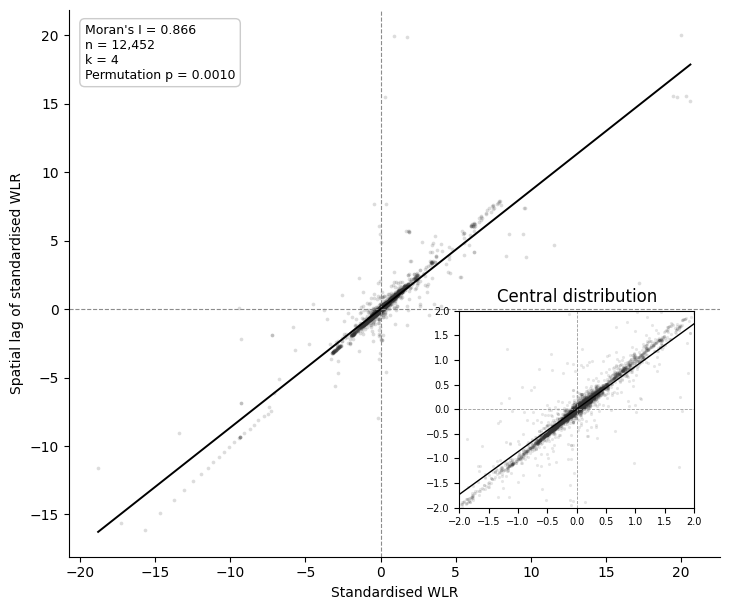

In [13]:
z = (wlr-wlr.mean())/wlr.std(ddof=0)
lag_z = lag_spatial(w_transects, z)
fig, ax = plt.subplots(figsize=(7.4,6.2))
ax.scatter(z,lag_z,s=7,c="0.20",alpha=0.17,linewidths=0,rasterized=True)
ax.axhline(0,color="0.55",ls="--",lw=0.8)
ax.axvline(0,color="0.55",ls="--",lw=0.8)
xx=np.linspace(z.min(),z.max(),200)
ax.plot(xx,moran_wlr.I*xx,color="black",lw=1.4)
ax.set(xlabel="Standardised WLR",ylabel="Spatial lag of standardised WLR")
ax.text(0.025,0.975,f"Moran's I = {moran_wlr.I:.3f}\nn = {len(wlr):,}\nk = {K_TRANSECT}\nPermutation p = {p_two_sided:.4f}",transform=ax.transAxes,ha="left",va="top",fontsize=9,bbox=dict(facecolor="white",edgecolor="0.8",boxstyle="round,pad=0.4"))
ins=ax.inset_axes([0.60,0.09,0.36,0.36]); mask=(np.abs(z)<=2)&(np.abs(lag_z)<=2)
ins.scatter(z[mask],lag_z[mask],s=5,c="0.2",alpha=0.12,linewidths=0,rasterized=True)
ins.axhline(0,color="0.6",ls="--",lw=0.6);ins.axvline(0,color="0.6",ls="--",lw=0.6)
ins.plot([-2,2],moran_wlr.I*np.array([-2,2]),color="black",lw=1)
ins.set(xlim=(-2,2),ylim=(-2,2),title="Central distribution")
ins.tick_params(labelsize=7)
ax.spines["top"].set_visible(False);ax.spines["right"].set_visible(False)
fig.tight_layout()
for ext in ["jpg"]:
    fig.savefig(GEO_OUT/f"Global_Moran_WLR_Scatter_Points.{ext}",dpi=600,bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
save_figure(fig, "Figure_6_Global_Morans_I_WLR_scatter")
plt.show()


### G5. LISA: local Moran’s I and significance
Use the **same** transects and `w_transects` as the global analysis. Four significant quadrant classes (HH, LL, LH, HL) plus a grey **Not significant** category are retained. p-values are unadjusted local permutation p-values, so treat site-specific clusters as exploratory until multiple-testing and weights sensitivity are assessed.

In [14]:


# ------------------------------------------------------------
# 1. Confirm input consistency
# ------------------------------------------------------------

assert len(gdf_moran) == len(wlr), "Transect and WLR lengths differ."
assert len(w_transects.neighbors) == len(wlr), "Weights and WLR lengths differ."

print("TRANSECT-LEVEL LISA")
print("=" * 60)
print("Transects:", len(wlr))
print("Spatial neighbours:", K_TRANSECT)

# ------------------------------------------------------------
# 2. Calculate Local Moran's I
# ------------------------------------------------------------

PERMUTATIONS_LISA = LISA_PERMUTATIONS

np.random.seed(SEED)

lisa_wlr = Moran_Local(
    wlr,
    w_transects,
    transformation="r",
    permutations=PERMUTATIONS_LISA,
    geoda_quads=True,
    n_jobs=1,
    keep_simulations=False
)

# ------------------------------------------------------------
# 3. Standardised WLR and spatial lag
# ------------------------------------------------------------

z = (wlr - wlr.mean()) / wlr.std(ddof=0)

lag_z = lag_spatial(w_transects, z)

# ------------------------------------------------------------
# 4. Identify significant LISA clusters
# ------------------------------------------------------------

# GeoDa quadrant convention:
# 1 = HH
# 2 = LL
# 3 = LH
# 4 = HL

quadrant_labels = {
    1: "High-High",
    2: "Low-Low",
    3: "Low-High",
    4: "High-Low"
}

significant = lisa_wlr.p_sim < ALPHA

cluster = np.full(
    len(wlr),
    "Not significant",
    dtype=object
)

for quadrant, label in quadrant_labels.items():

    mask = (
        significant
        & (lisa_wlr.q == quadrant)
    )

    cluster[mask] = label

# ------------------------------------------------------------
# 5. Attach results to transect GeoDataFrame
# ------------------------------------------------------------

gdf_lisa = gdf_moran.copy()

gdf_lisa["Local_I"] = lisa_wlr.Is
gdf_lisa["LISA_p"] = lisa_wlr.p_sim
gdf_lisa["LISA_q"] = lisa_wlr.q
gdf_lisa["WLR_z"] = z
gdf_lisa["WLR_spatial_lag"] = lag_z
gdf_lisa["LISA_cluster"] = cluster
gdf_lisa["LISA_significant"] = significant

# ------------------------------------------------------------
# 6. Summary statistics
# ------------------------------------------------------------

cluster_order = [
    "High-High",
    "Low-Low",
    "High-Low",
    "Low-High",
    "Not significant"
]

counts = (
    gdf_lisa["LISA_cluster"]
    .value_counts()
    .reindex(cluster_order, fill_value=0)
)

lisa_summary = pd.DataFrame({
    "Cluster": counts.index,
    "Transects": counts.values
})

lisa_summary["Percentage"] = (
    lisa_summary["Transects"]
    / len(gdf_lisa)
    * 100
)

print("\nLISA CLUSTER SUMMARY")
display(lisa_summary.round(2))

print(
    "\nTotal significant transects:",
    int(significant.sum())
)

print(
    "Percentage significant:",
    round(significant.mean() * 100, 2)
)

# ------------------------------------------------------------
# 7. Export results
# ------------------------------------------------------------

lisa_summary.to_csv(
    GEO_OUT / "Transect_LISA_Summary.csv",
    index=False
)

# CSV with geographic coordinates
gdf_lisa.drop(columns=gdf_lisa.geometry.name).to_csv(
    GEO_OUT / "Transect_LISA_Results.csv",
    index=False
)

# GeoPackage for QGIS / ArcGIS
remove_existing(GEO_OUT / "Transect_LISA_Clusters.gpkg")
gdf_lisa.to_crs("EPSG:4326").to_file(
    GEO_OUT / "Transect_LISA_Clusters.gpkg",
    layer="LISA_WLR",
    driver="GPKG"
)

print("\nOutputs saved to:", GEO_OUT)
save_table(lisa_summary, "Section_4.2.2_LISA_cluster_summary", folder=TEXT_STATS)


TRANSECT-LEVEL LISA
Transects: 12452
Spatial neighbours: 4

LISA CLUSTER SUMMARY


,Cluster,Transects,Percentage
0,High-High,776,6.23
1,Low-Low,694,5.57
2,High-Low,11,0.09
3,Low-High,15,0.12
4,Not significant,10956,87.99



Total significant transects: 1496
Percentage significant: 12.01

Outputs saved to: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\Geostatistics
Saved: Outputs\Tables\Text_statistics\Section_4.2.2_LISA_cluster_summary.csv


**Interpretation of the saved LISA output (k = 4; 999 permutations; unadjusted p < 0.05).** Of 12,452 transects, **776 (6.23%)** were HH, **694 (5.57%)** LL, **15 (0.12%)** LH and **11 (0.09%)** HL. **10,956 (87.99%)** were not significant. The four significant categories total **1,496 (12.01%)**. HH and LL indicate above- and below-mean WLR clusters, respectively, **not** erosion/accretion labels in themselves. Global significance does not imply that every location has a significant local cluster.


### G6. Separate LISA map
Plot four significant classes in colour and non-significant transects in grey, including grey in the legend. The map uses midpoint points; add coastline and administrative boundaries only from verified local layers. The map is exported **after** its final legend is constructed.

Saved: Outputs\Figures\Figure_7a_LISA_cluster_map.jpg


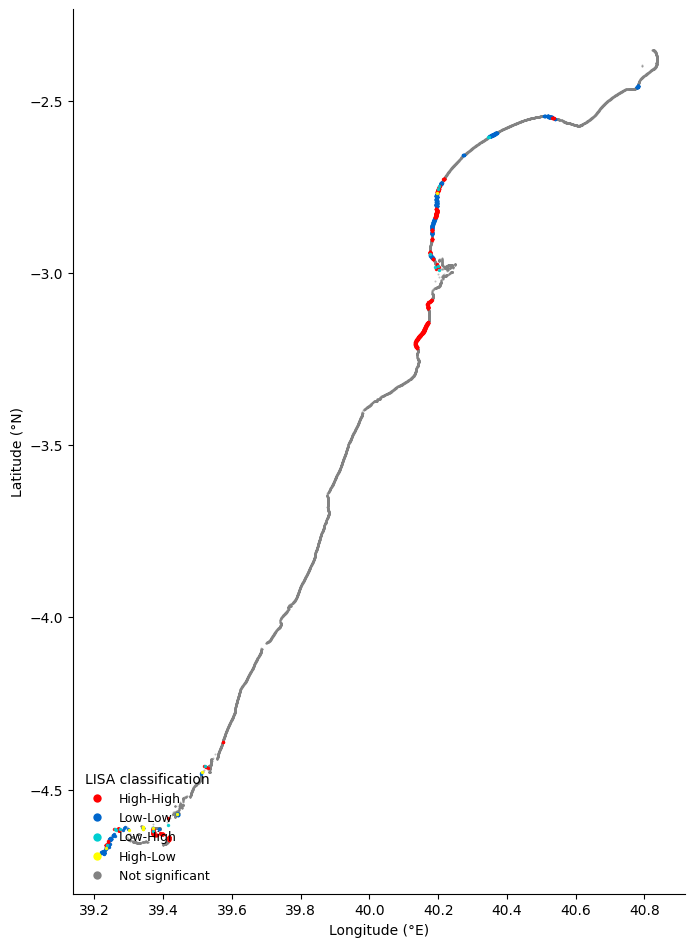

In [15]:
LISA_COLORS = {"High-High":"#FF0000","Low-Low":"#0066CC","Low-High":"#00CED1","High-Low":"#FFFF00","Not significant":"#828282"}
LISA_ORDER = ["High-High","Low-Low","Low-High","High-Low","Not significant"]
plot_gdf=gdf_lisa.to_crs("EPSG:4326")
fig,ax=plt.subplots(figsize=(7,10))
for label in ["Not significant","Low-Low","High-High","Low-High","High-Low"]:
    sub=plot_gdf.loc[plot_gdf.LISA_cluster.eq(label)]
    ax.scatter(sub.geometry.x,sub.geometry.y,s=2 if label=="Not significant" else 6,c=LISA_COLORS[label],alpha=0.5 if label=="Not significant" else 0.95,linewidths=0,rasterized=True)
handles=[Line2D([0],[0],marker="o",linestyle="none",markerfacecolor=LISA_COLORS[c],markeredgecolor="none",markersize=6,label=c) for c in LISA_ORDER]
ax.legend(handles=handles,title="LISA classification",loc="lower left",frameon=False,fontsize=9)
ax.set(xlabel="Longitude (°E)",ylabel="Latitude (°N)")
ax.set_aspect(1/np.cos(np.deg2rad(plot_gdf.geometry.y.mean())))
ax.spines["top"].set_visible(False);ax.spines["right"].set_visible(False)
fig.tight_layout()
for ext in ["jpg"]:fig.savefig(GEO_OUT/f"Transect_LISA_Cluster_Map.{ext}",dpi=600,bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
save_figure(fig, "Figure_7a_LISA_cluster_map")
plt.show()


### G7. Separate stacked LISA chart by zone
Each zone totals 100% **including Not significant**, using all valid WLR transects in that zone as denominator. This chart is separate from the map. The colours match the map and the study-zone names are read directly from `Zone`.

LISA_cluster,High-High,Low-Low,Low-High,High-Low,Not significant
Zone,,,,,
Kilifi,9.59,5.35,0.11,0.02,84.93
Kwale-Mombasa,5.98,5.55,0.18,0.26,88.03
Tana-Manda,0.65,6.00,0.06,0.00,93.29


Saved: Outputs\Figures\Figure_7b_LISA_clusters_by_zone.jpg


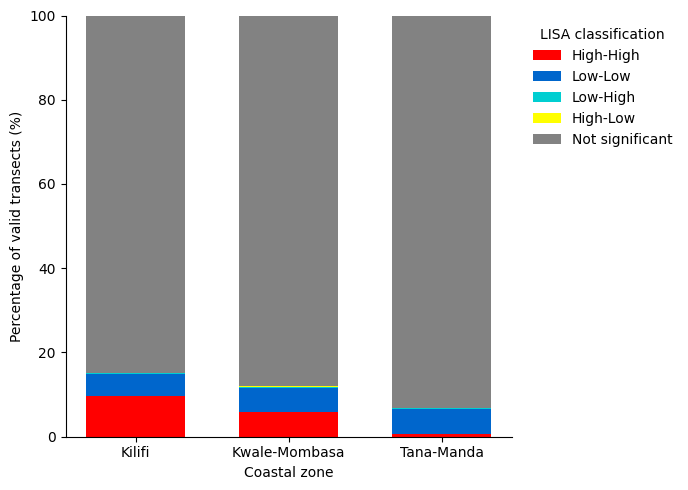

In [16]:
zone_order=["Kilifi","Kwale-Mombasa","Tana-Manda"]
counts=pd.crosstab(gdf_lisa["Zone"],gdf_lisa["LISA_cluster"]).reindex(index=zone_order,columns=LISA_ORDER,fill_value=0)
assert counts.sum(axis=1).gt(0).all(), "Missing zone; inspect Zone values."
pct=counts.div(counts.sum(axis=1),axis=0)*100
assert np.allclose(pct.sum(axis=1),100)
counts.to_csv(GEO_OUT/"LISA_Zone_Counts.csv")
pct.to_csv(GEO_OUT/"LISA_Zone_Percentages.csv")
display(pct.round(2))
fig,ax=plt.subplots(figsize=(7,5))
bottom=np.zeros(len(pct))
for label in LISA_ORDER:
    vals=pct[label].to_numpy()
    ax.bar(pct.index,vals,bottom=bottom,color=LISA_COLORS[label],label=label,width=0.65)
    bottom+=vals
ax.set(ylabel="Percentage of valid transects (%)",ylim=(0,100),xlabel="Coastal zone")
ax.spines["top"].set_visible(False);ax.spines["right"].set_visible(False)
ax.legend(frameon=False,bbox_to_anchor=(1.02,1),loc="upper left",title="LISA classification")
fig.tight_layout()
for ext in ["jpg"]:fig.savefig(GEO_OUT/f"LISA_Zone_Stacked_Percentages.{ext}",dpi=600,bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
save_figure(fig, "Figure_7b_LISA_clusters_by_zone")
plt.show()


## B. GLORYS-cell analysis (after LISA)

**Different analytical unit:** one observation per native `Pixel_ID` rather than per transect. The source notebook reads an **existing** `glorys_cell_geostatistical_input.csv`; it does not contain the cell-aggregation/export step that generated that file. Rebuild or verify its provenance, exclusion of `NEAREST_OCEAN_PROVISIONAL` assignments and WLR aggregation before using it for inference. The 47 cells are not independent replicates of transect-level sea level.

The GLORYS-cell Moran comparison below is supplementary spatial description, **not** the transect-level Moran’s I or LISA and **not** a WLR–sea-level correlation or regression.


In [17]:
# ============================================================
# B1. Rebuild GLORYS-cell geostatistical input
#     from FINAL primary transect dataset



# ------------------------------------------------------------
# 1. File paths
# ------------------------------------------------------------

DATA_FILE = CELL_INPUT_CSV

DATA_FILE.parent.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Confirm primary file exists
# ------------------------------------------------------------

if not PRIMARY_CSV.exists():
    raise FileNotFoundError(
        f"Primary transect dataset not found:\n{PRIMARY_CSV}"
    )

print("Primary dataset:")
print(PRIMARY_CSV)


# ------------------------------------------------------------
# 3. Load final transect dataset
# ------------------------------------------------------------

df = pd.read_csv(PRIMARY_CSV, low_memory=False)

print("\nPrimary dataset loaded.")
print(f"Total transects: {len(df):,}")


# ------------------------------------------------------------
# 4. Required fields
# ------------------------------------------------------------

required_cols = [
    "Transect_ID",
    "Pixel_ID",
    "Zone",
    "Grid_Lon",
    "Grid_Lat",
    "WLR",
    "EPR",
    "NSM",
    "SL_Trend_mm_yr",
    "SL_Variability_m"
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )


# ------------------------------------------------------------
# 5. Ensure analytical fields are numeric
# ------------------------------------------------------------

numeric_cols = [
    "Grid_Lon",
    "Grid_Lat",
    "WLR",
    "EPR",
    "NSM",
    "SL_Trend_mm_yr",
    "SL_Variability_m"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ------------------------------------------------------------
# 6. Retain transects assigned to GLORYS cells
# ------------------------------------------------------------

cell_source = df.dropna(
    subset=[
        "Pixel_ID",
        "Grid_Lon",
        "Grid_Lat",
        "SL_Trend_mm_yr",
        "SL_Variability_m"
    ]
).copy()

print(
    f"Transects assigned to GLORYS cells: "
    f"{len(cell_source):,}"
)

print(
    f"Unique GLORYS cells: "
    f"{cell_source['Pixel_ID'].nunique():,}"
)


# ------------------------------------------------------------
# 7. Check GLORYS attributes are constant within each cell
# ------------------------------------------------------------

validation = (
    cell_source
    .groupby("Pixel_ID")
    .agg(
        n_grid_lon=("Grid_Lon", "nunique"),
        n_grid_lat=("Grid_Lat", "nunique"),
        n_sl_trend=("SL_Trend_mm_yr", "nunique"),
        n_sl_variability=("SL_Variability_m", "nunique")
    )
)

problems = validation[
    (validation["n_grid_lon"] > 1) |
    (validation["n_grid_lat"] > 1) |
    (validation["n_sl_trend"] > 1) |
    (validation["n_sl_variability"] > 1)
]

if len(problems) > 0:
    print(
        "\nWARNING: Some cells contain inconsistent "
        "GLORYS attributes:"
    )
    display(problems)

else:
    print(
        "\nPASS: GLORYS attributes are consistent "
        "within all cells."
    )


# ------------------------------------------------------------
# 8. Aggregate shoreline statistics to GLORYS cells
# ------------------------------------------------------------

glorys = (
    cell_source
    .groupby("Pixel_ID", as_index=False)
    .agg(

        # Spatial information
        Zone=("Zone", "first"),
        Grid_Lon=("Grid_Lon", "first"),
        Grid_Lat=("Grid_Lat", "first"),

        # Transect counts
        n_transects=("Transect_ID", "size"),

        # GLORYS predictors
        SL_Trend_mm_yr=("SL_Trend_mm_yr", "first"),
        SL_Variability_m=("SL_Variability_m", "first"),

        # WLR statistics
        WLR_mean=("WLR", "mean"),
        WLR_median=("WLR", "median"),
        WLR_std=("WLR", "std"),
        WLR_min=("WLR", "min"),
        WLR_max=("WLR", "max"),
        WLR_n=("WLR", "count"),

        # EPR statistics
        EPR_mean=("EPR", "mean"),
        EPR_median=("EPR", "median"),
        EPR_std=("EPR", "std"),
        EPR_min=("EPR", "min"),
        EPR_max=("EPR", "max"),
        EPR_n=("EPR", "count"),

        # NSM statistics
        NSM_mean=("NSM", "mean"),
        NSM_median=("NSM", "median"),
        NSM_std=("NSM", "std"),
        NSM_min=("NSM", "min"),
        NSM_max=("NSM", "max"),
        NSM_n=("NSM", "count")
    )
)


# ------------------------------------------------------------
# 9. Final validation
# ------------------------------------------------------------

print("\nRebuilt GLORYS-cell dataset")
print("-" * 45)

print(f"Number of cells: {len(glorys):,}")
print(
    f"Total transects represented: "
    f"{glorys['n_transects'].sum():,}"
)
print(
    f"Valid WLR observations: "
    f"{glorys['WLR_n'].sum():,}"
)

print("\nMissing values in key variables:")

print(
    glorys[
        [
            "WLR_mean",
            "WLR_median",
            "SL_Trend_mm_yr",
            "SL_Variability_m"
        ]
    ].isna().sum()
)


# ------------------------------------------------------------
# 10. Check previously problematic cell
# ------------------------------------------------------------

print("\nCheck R024_C014:")

display(
    glorys.loc[
        glorys["Pixel_ID"] == "R024_C014"
    ].T
)


# ------------------------------------------------------------
# 11. Export using SAME OLD filename
# ------------------------------------------------------------

glorys.to_csv(
    DATA_FILE,
    index=False
)

print("\nSaved successfully:")
print(DATA_FILE)


Primary dataset:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\A_Shoreline\transect_primary_analysis.csv

Primary dataset loaded.
Total transects: 12,455
Transects assigned to GLORYS cells: 12,455
Unique GLORYS cells: 47

PASS: GLORYS attributes are consistent within all cells.

Rebuilt GLORYS-cell dataset
---------------------------------------------
Number of cells: 47
Total transects represented: 12,455
Valid WLR observations: 12,452

Missing values in key variables:
WLR_mean            0
WLR_median          0
SL_Trend_mm_yr      0
SL_Variability_m    0
dtype: int64

Check R024_C014:


,34
Pixel_ID,R024_C014
Zone,Kilifi
Grid_Lon,40.166668
Grid_Lat,-2.75
n_transects,163
SL_Trend_mm_yr,3.996499
SL_Variability_m,0.027614
WLR_mean,5.512837
WLR_median,-2.13469
WLR_std,14.858606



Saved successfully:
D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\B_GLORYS_Cell\glorys_cell_geostatistical_input.csv


In [18]:


# 1. Existing GLORYS-cell dataset

assert CELL_CSV.exists(), f"File not found: {CELL_CSV}"

cell = pd.read_csv(CELL_CSV, low_memory=False)

# 2. Identify WLR mean and median columns
# Supports alternative naming conventions

def find_column(df, candidates):
    for name in candidates:
        if name in df.columns:
            return name
    raise KeyError(
        f"None of these columns were found: {candidates}\n"
        f"Available columns: {df.columns.tolist()}"
    )

WLR_MEAN_COL = find_column(
    cell,
    ['WLR_mean', 'Mean_WLR']
)

WLR_MEDIAN_COL = find_column(
    cell,
    ['WLR_median', 'Median_WLR']
)

# 3. Variables for comparison
variables = {
    WLR_MEAN_COL: 'Mean WLR (m/yr)',
    WLR_MEDIAN_COL: 'Median WLR (m/yr)',
    'SL_Variability_m': 'Sea-level variability (m)',
    'SL_Trend_mm_yr': 'Sea-level trend (mm/yr)'
}

# 4. Validate required fields
required = [
    'Pixel_ID',
    'Grid_Lon',
    'Grid_Lat',
    *variables.keys()
]

missing = [
    col for col in required
    if col not in cell.columns
]

assert not missing, f"Missing required columns: {missing}"

# One observation per GLORYS grid cell
assert cell['Pixel_ID'].notna().all(), (
    "Missing Pixel_ID values."
)

assert cell['Pixel_ID'].is_unique, (
    "Duplicate Pixel_ID values detected. "
    "The dataset must contain one row per GLORYS cell."
)

# 5. Convert analysis fields to numeric
numeric_cols = [
    'Grid_Lon',
    'Grid_Lat',
    *variables.keys()
]

for col in numeric_cols:
    cell[col] = pd.to_numeric(
        cell[col],
        errors='coerce'
    )

cell = cell.replace(
    [np.inf, -np.inf],
    np.nan
)

# 6. Use identical GLORYS cells for all four variables
analysis = (
    cell.dropna(subset=numeric_cols)
    .copy()
    .reset_index(drop=True)
)

assert len(analysis) >= 6, (
    "Insufficient complete GLORYS cells."
)

# 7. Report
print("GLORYS CELL DATA LOADED")
print("=" * 55)

print("CSV:", CELL_CSV.resolve())
print("Original GLORYS cells:", len(cell))
print("Complete cells used:", len(analysis))
print("Cells excluded:", len(cell) - len(analysis))

print("\nVariables:")
for col, label in variables.items():
    print(f"  {col}: {label}")

display(
    analysis[
        ['Pixel_ID', *variables.keys()]
    ].head()
)


GLORYS CELL DATA LOADED
CSV: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Erosion_Geostats_summary\B_GLORYS_Cell\glorys_cell_geostatistical_input.csv
Original GLORYS cells: 47
Complete cells used: 47
Cells excluded: 0

Variables:
  WLR_mean: Mean WLR (m/yr)
  WLR_median: Median WLR (m/yr)
  SL_Variability_m: Sea-level variability (m)
  SL_Trend_mm_yr: Sea-level trend (mm/yr)


,Pixel_ID,WLR_mean,WLR_median,SL_Variability_m,SL_Trend_mm_yr
0,R001_C003,-3.028374,-2.101327,0.026099,3.870857
1,R001_C004,1.561604,0.649670,0.026230,3.907149
2,R001_C005,9.696548,1.613826,0.026408,3.945604
3,R002_C005,-0.224284,-0.033493,0.026407,3.940231
4,R003_C006,0.029786,-0.034746,0.026783,3.982604


## B1. GLORYS-cell geostatistical analysis

The relationship between long-term shoreline change and sea-level
characteristics was evaluated at the spatial resolution of the GLORYS
sea-level dataset. Shoreline transects falling within each GLORYS grid
cell were aggregated to provide cell-level shoreline-change statistics.

This approach avoids treating interpolated sea-level values assigned to
individual shoreline transects as independent observations. The resulting
dataset contains 47 GLORYS cells, each associated with sea-level trend,
sea-level variability, and summary statistics of shoreline change.

Both mean and median WLR are initially evaluated because the distribution
of shoreline-change rates within individual cells may be influenced by
extreme values. Subsequent model selection is therefore based on statistical
diagnostics and robustness rather than model fit alone.

## B2. Descriptive statistics of the corrected dataset

In [19]:
# ============================================================
# B2. Descriptive statistics
# ============================================================

analysis_vars = [
    "n_transects",
    "WLR_mean",
    "WLR_median",
    "WLR_std",
    "SL_Trend_mm_yr",
    "SL_Variability_m"
]

summary = glorys[analysis_vars].describe().T

display(summary.round(4))


,count,mean,std,min,25%,50%,75%,max
n_transects,47.0,265.0000,123.5947,3.0000,158.5000,297.0000,338.0000,555.0000
WLR_mean,47.0,0.2582,2.0629,-5.8663,-0.2211,0.0306,0.3529,9.6965
WLR_median,47.0,0.0178,0.9212,-2.1347,-0.1796,0.0258,0.1951,4.3831
WLR_std,47.0,2.1625,4.1471,0.0016,0.2304,0.6634,1.6236,17.9478
SL_Trend_mm_yr,47.0,3.9331,0.0462,3.8274,3.9048,3.9359,3.9642,4.0146
SL_Variability_m,47.0,0.0272,0.0004,0.0261,0.0271,0.0272,0.0276,0.0278


## B3. Inspect spatial extremes

In [20]:

cols = [
    "Pixel_ID",
    "Zone",
    "n_transects",
    "WLR_mean",
    "WLR_median",
    "WLR_std",
    "SL_Trend_mm_yr",
    "SL_Variability_m"
]

print("Largest positive mean WLR:")
display(
    glorys[cols]
    .sort_values("WLR_mean", ascending=False)
    .head(5)
)

print("\nLargest negative mean WLR:")
display(
    glorys[cols]
    .sort_values("WLR_mean")
    .head(5)
)

print("\nLargest absolute difference between mean and median:")
check = glorys[cols].copy()

check["Mean_Median_Difference"] = (
    check["WLR_mean"] - check["WLR_median"]
).abs()

display(
    check
    .sort_values("Mean_Median_Difference", ascending=False)
    .head(10)
)


Largest positive mean WLR:


,Pixel_ID,Zone,n_transects,WLR_mean,WLR_median,WLR_std,SL_Trend_mm_yr,SL_Variability_m
2,R001_C005,Kwale-Mombasa,236,9.696548,1.613826,17.947849,3.945604,0.026408
34,R024_C014,Kilifi,163,5.512837,-2.134690,14.858606,3.996499,0.027614
27,R019_C014,Kilifi,348,4.330152,4.383051,2.522088,3.898873,0.027597
1,R001_C004,Kwale-Mombasa,309,1.561604,0.649670,3.928682,3.907149,0.026230
28,R020_C014,Kilifi,304,1.034148,0.757167,1.570490,3.920336,0.027675



Largest negative mean WLR:


,Pixel_ID,Zone,n_transects,WLR_mean,WLR_median,WLR_std,SL_Trend_mm_yr,SL_Variability_m
40,R026_C018,Tana-Manda,294,-5.866269,-0.841532,15.977178,3.986337,0.027752
0,R001_C003,Kwale-Mombasa,376,-3.028374,-2.101327,9.616341,3.870857,0.026099
33,R023_C014,Kilifi,315,-1.275381,-1.861536,5.374726,3.980748,0.027630
38,R026_C016,Tana-Manda,248,-1.102641,-0.424066,2.862751,4.014558,0.027701
45,R028_C021,Tana-Manda,94,-1.040752,-0.812231,0.909819,3.831468,0.027082



Largest absolute difference between mean and median:


,Pixel_ID,Zone,n_transects,WLR_mean,WLR_median,WLR_std,SL_Trend_mm_yr,SL_Variability_m,Mean_Median_Difference
2,R001_C005,Kwale-Mombasa,236,9.696548,1.613826,17.947849,3.945604,0.026408,8.082722
34,R024_C014,Kilifi,163,5.512837,-2.134690,14.858606,3.996499,0.027614,7.647527
40,R026_C018,Tana-Manda,294,-5.866269,-0.841532,15.977178,3.986337,0.027752,5.024737
0,R001_C003,Kwale-Mombasa,376,-3.028374,-2.101327,9.616341,3.870857,0.026099,0.927048
1,R001_C004,Kwale-Mombasa,309,1.561604,0.649670,3.928682,3.907149,0.026230,0.911934
38,R026_C016,Tana-Manda,248,-1.102641,-0.424066,2.862751,4.014558,0.027701,0.678576
31,R022_C014,Kilifi,295,-0.323962,0.339229,3.433245,3.961079,0.027623,0.663191
29,R021_C014,Kilifi,235,0.935986,0.309721,5.415550,3.935924,0.027631,0.626265
33,R023_C014,Kilifi,315,-1.275381,-1.861536,5.374726,3.980748,0.027630,0.586155
6,R004_C007,Kwale-Mombasa,141,0.336712,-0.012089,0.733019,3.965181,0.027290,0.348801


## B4. Recalculate Pearson and Spearman relationships

In [21]:


responses = [
    "WLR_mean",
    "WLR_median"
]

predictors = [
    "SL_Trend_mm_yr",
    "SL_Variability_m"
]

results = []

for response in responses:
    for predictor in predictors:

        tmp = glorys[
            [response, predictor]
        ].dropna()

        pearson_r, pearson_p = pearsonr(
            tmp[predictor],
            tmp[response]
        )

        spearman_rho, spearman_p = spearmanr(
            tmp[predictor],
            tmp[response]
        )

        results.append({
            "Response": response,
            "Predictor": predictor,
            "n": len(tmp),
            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman_rho": spearman_rho,
            "Spearman_p": spearman_p
        })

correlation_results = pd.DataFrame(results)

display(
    correlation_results.round(4)
)
save_table(correlation_results, "Section_4.2.3_Correlations", folder=TEXT_STATS)


,Response,Predictor,n,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,WLR_mean,SL_Trend_mm_yr,47,0.0371,0.8045,-0.0398,0.7907
1,WLR_mean,SL_Variability_m,47,-0.1681,0.2587,-0.2179,0.1413
2,WLR_median,SL_Trend_mm_yr,47,-0.0924,0.5367,-0.1177,0.4307
3,WLR_median,SL_Variability_m,47,-0.0044,0.9767,-0.2091,0.1584


Saved: Outputs\Tables\Text_statistics\Section_4.2.3_Correlations.csv


## Below we proceed with Geostatistics.
Analysis Report: Preliminary Assessment of Shoreline Change and GLORYS Sea-Level Metrics
Key Findings

The most significant outcome of the analysis is that GLORYS sea-level trend and sea-level variability do not exhibit a statistically significant bivariate relationship with cell-level shoreline change. Across all tests performed, the observed associations were weak and failed to reach conventional significance thresholds. Specifically:

All Pearson correlation tests returned p-values greater than 0.25.
All Spearman rank correlation tests returned p-values greater than 0.14.
Correlation coefficients were consistently small, indicating only negligible relationships between GLORYS-derived sea-level metrics and shoreline change indicators.

These results suggest that, based on the current dataset and analytical approach, neither long-term sea-level trends nor sea-level variability can be considered meaningful predictors of shoreline change at the cell level.

## Section B5. Fit the four OLS models

In [22]:


model_specs = {
    "M1: Mean WLR ~ SL trend":
        ("WLR_mean", "SL_Trend_mm_yr"),

    "M2: Mean WLR ~ SL variability":
        ("WLR_mean", "SL_Variability_m"),

    "M3: Median WLR ~ SL trend":
        ("WLR_median", "SL_Trend_mm_yr"),

    "M4: Median WLR ~ SL variability":
        ("WLR_median", "SL_Variability_m")
}

ols_models = {}
ols_results = []

for name, (response, predictor) in model_specs.items():

    data = glorys[
        [response, predictor]
    ].dropna()

    X = sm.add_constant(data[[predictor]])
    y = data[response]

    model = sm.OLS(y, X).fit()

    ols_models[name] = model

    ols_results.append({
        "Model": name,
        "n": int(model.nobs),
        "Intercept": model.params["const"],
        "Slope": model.params[predictor],
        "SE_slope": model.bse[predictor],
        "t": model.tvalues[predictor],
        "p": model.pvalues[predictor],
        "R2": model.rsquared,
        "Adjusted_R2": model.rsquared_adj,
        "F": model.fvalue,
        "F_p": model.f_pvalue,
        "AIC": model.aic,
        "BIC": model.bic
    })

ols_table = pd.DataFrame(ols_results)

display(
    ols_table.round({
        "Intercept": 4,
        "Slope": 4,
        "SE_slope": 4,
        "t": 3,
        "p": 4,
        "R2": 4,
        "Adjusted_R2": 4,
        "F": 3,
        "F_p": 4,
        "AIC": 2,
        "BIC": 2
    })
)
save_table(ols_table, "Section_4.2.3_OLS_results", folder=TEXT_STATS)


,Model,n,Intercept,Slope,SE_slope,t,p,R2,Adjusted_R2,F,F_p,AIC,BIC
0,M1: Mean WLR ~ SL trend,47,-6.2557,1.6562,6.6514,0.249,0.8045,0.0014,-0.0208,0.062,0.8045,204.37,208.07
1,M2: Mean WLR ~ SL variability,47,23.4116,-850.0069,743.0229,-1.144,0.2587,0.0283,0.0067,1.309,0.2587,203.09,206.79
2,M3: Median WLR ~ SL trend,47,7.2640,-1.8424,2.9594,-0.623,0.5367,0.0085,-0.0135,0.388,0.5367,128.25,131.95
3,M4: Median WLR ~ SL variability,47,0.2869,-9.8804,336.5714,-0.029,0.9767,0.0000,-0.0222,0.001,0.9767,128.65,132.35


Saved: Outputs\Tables\Text_statistics\Section_4.2.3_OLS_results.csv


Saved: Outputs\Figures\Figure_8_OLS_mean_WLR_vs_GLORYS_sea_level.jpg


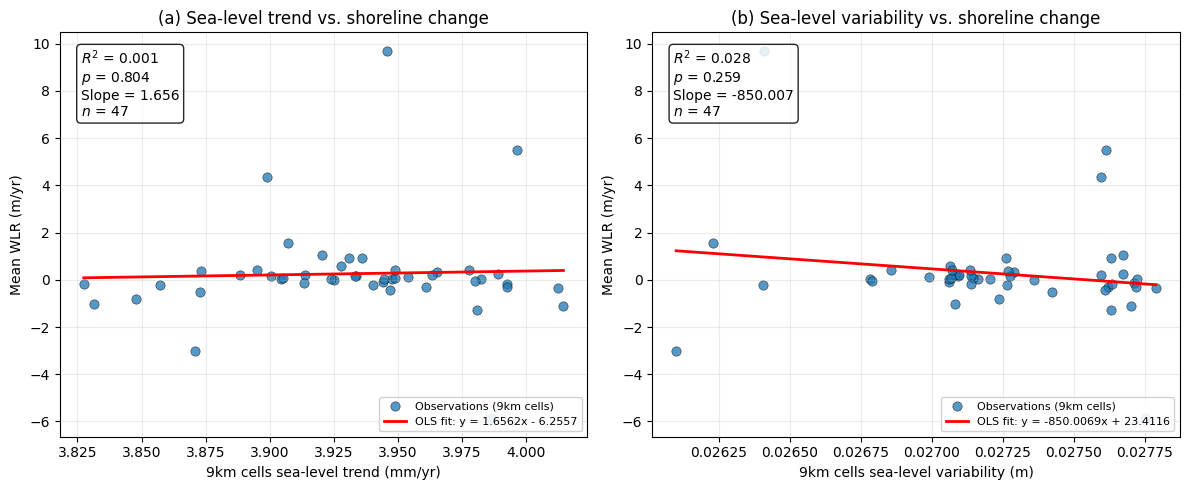

In [23]:
# ============================================================
# B5. OLS regression figure
# GLORYS sea-level characteristics vs mean WLR
# ============================================================


fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

plot_specs = [
    (
        axes[0],
        "SL_Trend_mm_yr",
        "WLR_mean",
        ols_models["M1: Mean WLR ~ SL trend"],
        "9km cells sea-level trend (mm/yr)",
        "(a) Sea-level trend vs. shoreline change"
    ),
    (
        axes[1],
        "SL_Variability_m",
        "WLR_mean",
        ols_models["M2: Mean WLR ~ SL variability"],
        "9km cells sea-level variability (m)",
        "(b) Sea-level variability vs. shoreline change"
    )
]

for ax, xvar, yvar, model, xlabel, title in plot_specs:
    x = glorys[xvar]
    y = glorys[yvar]

    # Observations
    ax.scatter(
        x, y,
        s=45, alpha=0.75, edgecolor="black", linewidth=0.4,
        label="Observations (9km cells)"
    )

    # Regression line
    x_line = np.linspace(x.min(), x.max(), 200)
    intercept = model.params["const"]
    slope = model.params[xvar]
    y_line = intercept + slope * x_line

    # Fitted-equation string, shown via the legend rather than a separate annotation
    sign = "+" if intercept >= 0 else "-"
    eqn = f"y = {slope:.4f}x {sign} {abs(intercept):.4f}"

    ax.plot(
        x_line, y_line,
        color="red", linewidth=2,
        label=f"OLS fit: {eqn}"
    )

    # Model statistics
    pval = model.pvalues[xvar]
    r2 = model.rsquared
    stats_text = (
        f"$R^2$ = {r2:.3f}\n"
        f"$p$ = {pval:.3f}\n"
        f"Slope = {slope:.3f}\n"
        f"$n$ = {int(model.nobs)}"
    )
    ax.text(
        0.04, 0.96,
        stats_text,
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Mean WLR (m/yr)")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right", fontsize=8, framealpha=0.9)

plt.tight_layout()
save_figure(fig, "Figure_8_OLS_mean_WLR_vs_GLORYS_sea_level")
plt.show()


OLS relationships between mean shoreline change rate (WLR) and GLORYS-derived (a) sea-level trend and (b) sea-level variability across 47 native GLORYS grid cells along the Kenyan coast. Red lines represent the fitted OLS regressions. Neither relationship was statistically significant

# B6. Spatial autocorrelation of OLS residuals 
 Primary mean-WLR models

In [24]:
# ============================================================

# ============================================================



# ------------------------------------------------------------
# 1. Coordinates of the 47 native GLORYS cells
# ------------------------------------------------------------

coords = glorys[
    ["Grid_Lon", "Grid_Lat"]
].to_numpy()

# ------------------------------------------------------------
# 2. Construct k = 4 nearest-neighbour weights
# ------------------------------------------------------------

w4 = KNN.from_array(
    coords,
    k=4
)

w4.transform = "R"

print(f"Number of GLORYS cells: {w4.n}")
print(f"Minimum neighbours: {w4.min_neighbors}")
print(f"Maximum neighbours: {w4.max_neighbors}")
print(f"Mean neighbours: {w4.mean_neighbors:.2f}")


# ------------------------------------------------------------
# 3. Moran's I for residuals of primary OLS models
# ------------------------------------------------------------

primary_models = {
    "Mean WLR ~ SL trend":
        ols_models["M1: Mean WLR ~ SL trend"],

    "Mean WLR ~ SL variability":
        ols_models["M2: Mean WLR ~ SL variability"]
}

moran_results = []

for name, model in primary_models.items():

    residuals = np.asarray(
        model.resid
    ).flatten()

    moran = Moran(
        residuals,
        w4,
        permutations=999
    )

    moran_results.append({
        "Model": name,
        "n": len(residuals),
        "Moran_I": moran.I,
        "Expected_I": moran.EI,
        "Pseudo_p": moran.p_sim,
        "z_sim": moran.z_sim
    })

moran_table = pd.DataFrame(
    moran_results
)

display(
    moran_table.round({
        "Moran_I": 4,
        "Expected_I": 4,
        "Pseudo_p": 4,
        "z_sim": 3
    })
)
save_table(moran_table, "Section_4.2.3_OLS_residual_Morans_I", folder=TEXT_STATS)


Number of GLORYS cells: 47
Minimum neighbours: 4
Maximum neighbours: 4
Mean neighbours: 4.00


,Model,n,Moran_I,Expected_I,Pseudo_p,z_sim
0,Mean WLR ~ SL trend,47,-0.0091,-0.0217,0.404,0.151
1,Mean WLR ~ SL variability,47,-0.0624,-0.0217,0.306,-0.489


Saved: Outputs\Tables\Text_statistics\Section_4.2.3_OLS_residual_Morans_I.csv


# B6b. Residual Moran's I sensitivity to KNN specification

In [25]:


sensitivity_results = []

for k in [2, 4, 6]:

    w = KNN.from_array(
        coords,
        k=k
    )

    w.transform = "R"

    for name, model in primary_models.items():

        residuals = np.asarray(
            model.resid
        ).flatten()

        moran = Moran(
            residuals,
            w,
            permutations=999
        )

        sensitivity_results.append({
            "Model": name,
            "k": k,
            "Moran_I": moran.I,
            "Pseudo_p": moran.p_sim
        })

moran_sensitivity = pd.DataFrame(
    sensitivity_results
)

display(
    moran_sensitivity.round({
        "Moran_I": 4,
        "Pseudo_p": 4
    })
)


,Model,k,Moran_I,Pseudo_p
0,Mean WLR ~ SL trend,2,-0.0043,0.407
1,Mean WLR ~ SL variability,2,-0.0870,0.250
2,Mean WLR ~ SL trend,4,-0.0091,0.433
3,Mean WLR ~ SL variability,4,-0.0624,0.333
4,Mean WLR ~ SL trend,6,0.0008,0.343
5,Mean WLR ~ SL variability,6,-0.0249,0.494


Interpretation: Spatial autocorrelation of OLS residuals. Moran's I indicated no significant spatial autocorrelation in the residuals of either OLS model using four-nearest-neighbour spatial weights (sea-level trend: I = −0.009, p = 0.404; sea-level variability: I = −0.062, p = 0.306). This result was consistent under sensitivity tests using k = 2, 4, and 6 nearest neighbours, indicating that the OLS residuals did not exhibit significant remaining spatial dependence. THus SLM was not statisticall warranted

Instead, we fit the spatial lag model as a comparative sensitivity model, not because OLS requires spatial correction. This lets us determine what happens to the old SLM result when the analysis is performed correctly at native GLORYS-cell support.

## B7. Spatial Lag Model at native GLORYS-cell support

In [26]:
# ============================================================
# B7. Spatial Lag Model
# Comparative spatial-model analysis
# ============================================================


slm_specs = {
    "SLM1: Mean WLR ~ SL trend":
        "SL_Trend_mm_yr",

    "SLM2: Mean WLR ~ SL variability":
        "SL_Variability_m"
}

slm_models = {}
slm_results = []

for name, predictor in slm_specs.items():

    # --------------------------------------------------------
    # Dependent variable
    # --------------------------------------------------------
    y = glorys[["WLR_mean"]].to_numpy()

    # Predictor
    X = glorys[[predictor]].to_numpy()

    # --------------------------------------------------------
    # Spatial lag model
    # --------------------------------------------------------
    model = ML_Lag(
        y,
        X,
        w=w4,
        name_y="WLR_mean",
        name_x=[predictor],
        name_w="KNN k=4"
    )

    slm_models[name] = model

    # --------------------------------------------------------
    # Extract coefficients safely
    #
    # betas:
    # [0] = intercept
    # [1] = sea-level predictor
    # [2] = spatial lag coefficient (rho)
    # --------------------------------------------------------

    intercept = model.betas[0].item()
    slope = model.betas[1].item()

    # rho is available directly from model.rho
    rho = np.asarray(model.rho).item()

    slope_p = model.z_stat[1][1]
    rho_p = model.z_stat[-1][1]

    slm_results.append({
        "Model": name,
        "n": model.n,
        "Intercept": intercept,
        "Slope": slope,
        "Slope_p": slope_p,
        "Rho": rho,
        "Rho_p": rho_p,
        "Pseudo_R2": model.pr2,
        "LogLik": model.logll,
        "AIC": model.aic,
        "BIC": model.schwarz
    })


# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

slm_table = pd.DataFrame(slm_results)

display(
    slm_table.round({
        "Intercept": 4,
        "Slope": 4,
        "Slope_p": 4,
        "Rho": 4,
        "Rho_p": 4,
        "Pseudo_R2": 4,
        "LogLik": 2,
        "AIC": 2,
        "BIC": 2
    })
)
save_table(slm_table, "Section_4.2.4_Spatial_lag_model", folder=TEXT_STATS)


,Model,n,Intercept,Slope,Slope_p,Rho,Rho_p,Pseudo_R2,LogLik,AIC,BIC
0,SLM1: Mean WLR ~ SL trend,47,-6.1240,1.6241,0.8030,-0.0233,0.9125,0.0018,-100.18,206.36,211.91
1,SLM2: Mean WLR ~ SL variability,47,27.4939,-998.8195,0.1776,-0.1271,0.5632,0.0385,-99.39,204.78,210.33


Saved: Outputs\Tables\Text_statistics\Section_4.2.4_Spatial_lag_model.csv


In [27]:
# ============================================================
# B7b. Full SLM model summaries
# ============================================================

for name, model in slm_models.items():

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    print(model.summary)



SLM1: Mean WLR ~ SL trend
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
-----------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     KNN k=4
Dependent Variable  :    WLR_mean                Number of Observations:          47
Mean dependent var  :      0.2582                Number of Variables   :           3
S.D. dependent var  :      2.0629                Degrees of Freedom    :          44
Pseudo R-squared    :      0.0018
Spatial Pseudo R-squared:  0.0015
Log likelihood      :   -100.1806
Sigma-square ML     :      4.1579                Akaike info criterion :     206.361
S.E of regression   :      2.0391                Schwarz criterion     :     211.912

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------

Spatial lag modelling similarly provided little evidence of spatial dependence in shoreline change at the GLORYS grid-cell scale. For the sea-level trend model, the spatial autoregressive coefficient was small and non-significant (ρ = −0.023, p = 0.912), while sea-level trend was also non-significant (β = 1.624, p = 0.803; pseudo-R² = 0.002). For sea-level variability, the spatial lag coefficient remained non-significant (ρ = −0.127, p = 0.563), as did the sea-level variability coefficient (β = −998.820, p = 0.178; pseudo-R² = 0.039). These results were consistent with the absence of significant spatial autocorrelation in the OLS residuals.

## B8 GWR

In [28]:
# ============================================================
# B8. Geographically Weighted Regression
# Native GLORYS-cell analysis
# ============================================================




# ------------------------------------------------------------
# Coordinates
# ------------------------------------------------------------

coords_gwr = list(
    zip(
        glorys["Grid_Lon"],
        glorys["Grid_Lat"]
    )
)


# ------------------------------------------------------------
# GWR specifications
# ------------------------------------------------------------

gwr_specs = {
    "GWR1: Mean WLR ~ SL trend":
        "SL_Trend_mm_yr",

    "GWR2: Mean WLR ~ SL variability":
        "SL_Variability_m"
}


gwr_models = {}
gwr_results = []


for name, predictor in gwr_specs.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    # Response
    y = glorys[
        ["WLR_mean"]
    ].to_numpy()

    # Predictor
    X = glorys[
        [predictor]
    ].to_numpy()

    # --------------------------------------------------------
    # Select adaptive bandwidth
    # --------------------------------------------------------

    selector = Sel_BW(
        coords_gwr,
        y,
        X,
        fixed=False,
        spherical=True
    )

    bw = selector.search()

    print(
        f"Selected adaptive bandwidth: {bw}"
    )

    # --------------------------------------------------------
    # Fit GWR
    # --------------------------------------------------------

    gwr = GWR(
        coords_gwr,
        y,
        X,
        bw=bw,
        fixed=False,
        spherical=True
    ).fit()

    gwr_models[name] = gwr

    # Local predictor coefficients
    local_beta = gwr.params[:, 1]

    gwr_results.append({
        "Model": name,

        "Bandwidth":
            bw,

        "R2":
            gwr.R2,

        "Adjusted_R2":
            gwr.adj_R2,

        "AICc":
            gwr.aicc,

        "Beta_min":
            np.min(local_beta),

        "Beta_max":
            np.max(local_beta),

        "Beta_mean":
            np.mean(local_beta),

        "Beta_median":
            np.median(local_beta),

        "Beta_SD":
            np.std(
                local_beta,
                ddof=1
            ),

        "Positive_n":
            np.sum(local_beta > 0),

        "Negative_n":
            np.sum(local_beta < 0)
    })


gwr_table = pd.DataFrame(
    gwr_results
)

display(
    gwr_table.round(4)
)
save_table(gwr_table, "Section_4.2.5_GWR", folder=TEXT_STATS)



GWR1: Mean WLR ~ SL trend
Selected adaptive bandwidth: 46.0

GWR2: Mean WLR ~ SL variability
Selected adaptive bandwidth: 46.0


,Model,Bandwidth,R2,Adjusted_R2,AICc,Beta_min,Beta_max,Beta_mean,Beta_median,Beta_SD,Positive_n,Negative_n
0,GWR1: Mean WLR ~ SL trend,46.0,0.0532,-0.0258,208.1688,-4.5617,9.5163,0.7318,-1.1671,4.3303,16,31
1,GWR2: Mean WLR ~ SL variability,46.0,0.0449,-0.0271,207.7877,-671.7490,492.9456,-324.3446,-389.2058,287.1657,7,40


Saved: Outputs\Tables\Text_statistics\Section_4.2.5_GWR.csv


In [29]:
# ============================================================
# B8b. GWR summaries
# ============================================================

for name, model in gwr_models.items():

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    print(model.summary())



GWR1: Mean WLR ~ SL trend
Model type                                                         Gaussian
Number of observations:                                                  47
Number of covariates:                                                     2

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            195.495
Log-likelihood:                                                    -100.187
AIC:                                                                204.373
AICc:                                                               206.931
BIC:                                                                 22.238
R2:                                                                   0.001
Adj. R2:                                                             -0.021

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- -

Geographically weighted regression did not provide evidence of substantial improvement over the global models. The optimized adaptive bandwidth was 46 nearest observations for both sea-level trend and sea-level variability, effectively approaching the full sample of 47 GLORYS cells. The trend model produced an R² of 0.053 and an adjusted R² of −0.026, while the variability model produced an R² of 0.045 and an adjusted R² of −0.027. The large optimized bandwidth and negative adjusted R² values indicate limited support for geographically varying relationships between the GLORYS-derived sea-level metrics and mean shoreline change. Consequently, local GWR coefficients were not interpreted as evidence of localized sea-level effects.